In [1]:
import torch
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
df=pd.read_csv("../Iris.csv")

In [3]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 150 entries, 0 to 149
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             150 non-null    int64  
 1   SepalLengthCm  150 non-null    float64
 2   SepalWidthCm   150 non-null    float64
 3   PetalLengthCm  150 non-null    float64
 4   PetalWidthCm   150 non-null    float64
 5   Species        150 non-null    str    
dtypes: float64(4), int64(1), str(1)
memory usage: 9.1 KB


In [5]:
df["Species"].value_counts()

Species
Iris-setosa        50
Iris-versicolor    50
Iris-virginica     50
Name: count, dtype: int64

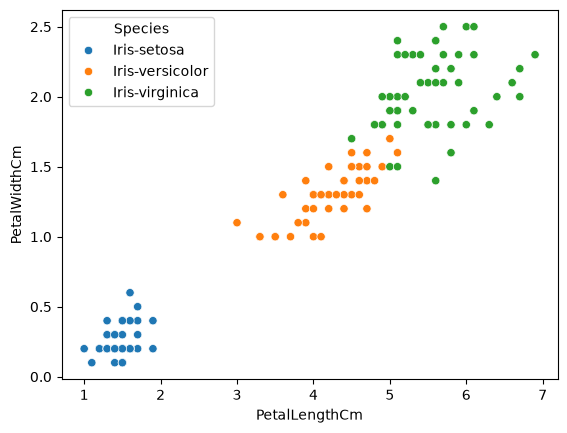

In [6]:
sns.scatterplot(data=df,x="PetalLengthCm",y="PetalWidthCm",hue="Species")
plt.show()

In [7]:
df.head()

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa
3,4,4.6,3.1,1.5,0.2,Iris-setosa
4,5,5.0,3.6,1.4,0.2,Iris-setosa


In [8]:
df.drop("Id",axis=1,inplace=True)

In [9]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [10]:
X=df[["SepalLengthCm","SepalWidthCm","PetalLengthCm","PetalWidthCm"]].values
y=df["Species"].values

In [11]:
y

<ArrowStringArray>
[   'Iris-setosa',    'Iris-setosa',    'Iris-setosa',    'Iris-setosa',
    'Iris-setosa',    'Iris-setosa',    'Iris-setosa',    'Iris-setosa',
    'Iris-setosa',    'Iris-setosa',
 ...
 'Iris-virginica', 'Iris-virginica', 'Iris-virginica', 'Iris-virginica',
 'Iris-virginica', 'Iris-virginica', 'Iris-virginica', 'Iris-virginica',
 'Iris-virginica', 'Iris-virginica']
Length: 150, dtype: str

In [12]:
from sklearn.preprocessing import LabelEncoder

In [13]:
label_encoder=LabelEncoder()
y=label_encoder.fit_transform(y)

In [14]:
y

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [15]:
from sklearn.model_selection import train_test_split

In [16]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

In [17]:
y_test

array([0, 2, 1, 1, 0, 1, 0, 0, 2, 1, 2, 2, 2, 1, 0, 0, 0, 1, 1, 2, 0, 2,
       1, 2, 2, 1, 1, 0, 2, 0])

In [18]:
X_train=torch.tensor(X_train,dtype=torch.float32)
X_test=torch.tensor(X_test,dtype=torch.float32)

y_train=torch.tensor(y_train,dtype=torch.long)
y_test=torch.tensor(y_test,dtype=torch.long)

In [19]:
print(X_train.shape,X_test.shape)
print(y_train.shape,y_test.shape)

torch.Size([120, 4]) torch.Size([30, 4])
torch.Size([120]) torch.Size([30])


In [20]:
from torch import nn

In [21]:
class IrısClassifier(nn.Module):
    def __init__(self):
        super().__init__()

        self.layer1=nn.Linear(in_features=4,out_features=16)
        self.layer2=nn.Linear(in_features=16,out_features=16)
        self.layer3=nn.Linear(in_features=16,out_features=3)
        self.relu=nn.ReLU()
    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.layer3(self.relu(self.layer2(self.relu(self.layer1(x)))))

In [22]:
class IrısClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.linear_layer_stack=nn.Sequential(
            nn.Linear(4,16),
            nn.ReLU(),
            nn.Linear(16,16),
            nn.ReLU(),
            nn.Linear(16,3)
        )

    def forward(self,x:torch.Tensor)->torch.Tensor:
        return self.linear_layer_stack(x)

In [23]:
torch.manual_seed(42)
model=IrısClassifier()
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(params=model.parameters(),lr=0.01)

In [24]:
def calculate_accuarcy(y_true,y_pred):
    correct=torch.eq(y_true,y_pred).sum().item()
    acc=correct/len(y_pred)*100
    return acc

In [25]:
model(X_test)[:5]

tensor([[ 0.0301, -0.2353, -0.1655],
        [ 0.0441, -0.2396, -0.2402],
        [ 0.0442, -0.1847, -0.2030],
        [ 0.0449, -0.1844, -0.1990],
        [ 0.0281, -0.2419, -0.1650]], grad_fn=<SliceBackward0>)

In [26]:
model(X_test)[:5].shape

torch.Size([5, 3])

In [27]:
y_logits=model(X_test)
y_pred_probs=torch.softmax(y_logits,dim=1)

In [28]:
y_logits[:5]

tensor([[ 0.0301, -0.2353, -0.1655],
        [ 0.0441, -0.2396, -0.2402],
        [ 0.0442, -0.1847, -0.2030],
        [ 0.0449, -0.1844, -0.1990],
        [ 0.0281, -0.2419, -0.1650]], grad_fn=<SliceBackward0>)

In [29]:
y_pred_probs[:5]

tensor([[0.3862, 0.2962, 0.3176],
        [0.3991, 0.3005, 0.3004],
        [0.3881, 0.3087, 0.3031],
        [0.3878, 0.3083, 0.3039],
        [0.3864, 0.2950, 0.3186]], grad_fn=<SliceBackward0>)

In [30]:
torch.sum(y_pred_probs[4])

tensor(1., grad_fn=<SumBackward0>)

In [31]:
torch.softmax(y_logits,dim=1).argmax(dim=1)

tensor([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
        0, 0, 0, 0, 0, 0])

In [32]:
epochs=200

train_losses=[]
test_losses=[]
train_accuracies=[]
test_accuracies=[]

for epoch in range(epochs):
    model.train()
    
    logits=model(X_train)
    pred=torch.softmax(logits,dim=1).argmax(dim=1)

    loss=loss_fn(logits,y_train)
    acc=calculate_accuarcy(y_true=y_train,y_pred=pred)

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()

    train_losses.append(loss.item())
    train_accuracies.append(acc)
    
    
    model.eval()
    with torch.inference_mode():
        test_logits=model(X_test)
        test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)

        test_loss=loss_fn(test_logits,y_test)
        test_acc=calculate_accuarcy(y_true=y_test,y_pred=test_pred)
    test_losses.append(test_loss.item())
    test_accuracies.append(test_acc)
    if epoch % 20==0:
        print(f"Epoch{epoch} Train loss:{loss} ,Train Acc:{acc},Test loss:{test_loss},Test Acc:{test_acc}")

Epoch0 Train loss:1.1047419309616089 ,Train Acc:33.33333333333333,Test loss:1.0136786699295044,Test Acc:66.66666666666666
Epoch20 Train loss:0.4823397397994995 ,Train Acc:66.66666666666666,Test loss:0.4637943506240845,Test Acc:70.0
Epoch40 Train loss:0.1671018898487091 ,Train Acc:97.5,Test loss:0.16651225090026855,Test Acc:100.0
Epoch60 Train loss:0.0662829652428627 ,Train Acc:97.5,Test loss:0.06135140359401703,Test Acc:100.0
Epoch80 Train loss:0.05698041990399361 ,Train Acc:98.33333333333333,Test loss:0.04562463238835335,Test Acc:100.0
Epoch100 Train loss:0.053733404725790024 ,Train Acc:98.33333333333333,Test loss:0.043743476271629333,Test Acc:100.0
Epoch120 Train loss:0.051568035036325455 ,Train Acc:98.33333333333333,Test loss:0.04341859742999077,Test Acc:100.0
Epoch140 Train loss:0.04973548278212547 ,Train Acc:98.33333333333333,Test loss:0.04335939884185791,Test Acc:100.0
Epoch160 Train loss:0.04813370853662491 ,Train Acc:98.33333333333333,Test loss:0.0440792590379715,Test Acc:100.0

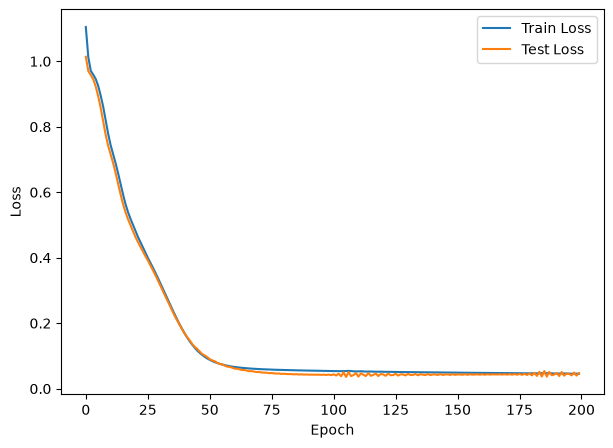

In [33]:
plt.figure(figsize=(7,5))
plt.plot(train_losses,label="Train Loss")
plt.plot(test_losses,label="Test Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

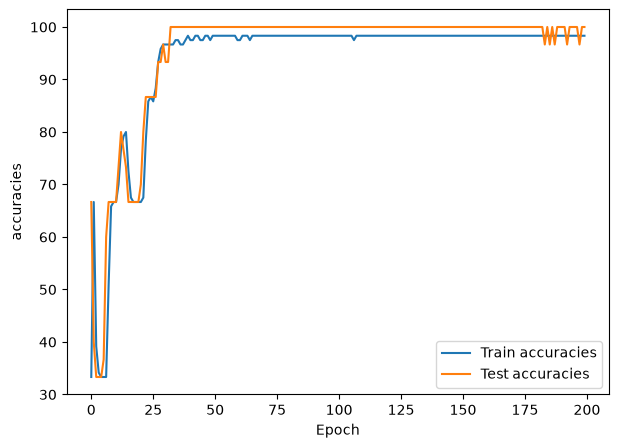

In [34]:
plt.figure(figsize=(7,5))
plt.plot(train_accuracies,label="Train accuracies")
plt.plot(test_accuracies,label="Test accuracies")
plt.xlabel("Epoch")
plt.ylabel("accuracies")
plt.legend()
plt.show()

In [35]:
df.head()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,5.1,3.5,1.4,0.2,Iris-setosa
1,4.9,3.0,1.4,0.2,Iris-setosa
2,4.7,3.2,1.3,0.2,Iris-setosa
3,4.6,3.1,1.5,0.2,Iris-setosa
4,5.0,3.6,1.4,0.2,Iris-setosa


In [36]:
new_sample=np.array([[5.1,3.5,1.4,0.2]])

In [37]:
new_sample_tensor=torch.tensor(new_sample,dtype=torch.float32)

In [38]:
new_sample_tensor.shape

torch.Size([1, 4])

In [39]:
model.eval()
with torch.inference_mode():
    logits=model(new_sample_tensor)
    probs=torch.softmax(logits,dim=1)
    predicted_class=torch.argmax(probs,dim=1).item()

In [40]:
print(predicted_class)

0


In [41]:
label_encoder.inverse_transform([predicted_class])[0]

'Iris-setosa'

In [42]:
!pip install torchmetrics

In [43]:
from torchmetrics.classification import MulticlassAccuracy

In [44]:
accuarcy=MulticlassAccuracy(num_classes=3)

In [45]:
epochs=200
model2=IrısClassifier()
loss_fn=nn.CrossEntropyLoss()
optimizer=torch.optim.Adam(params=model2.parameters(),lr=0.01)

for epoch in range(epochs):

    model2.train()
    logits=model2(X_train)
    loss=loss_fn(logits,y_train)

    pred=torch.softmax(logits,dim=1).argmax(dim=1)
    acc=accuarcy(pred,y_train).item()*100

    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    with torch.inference_mode():
        test_logits=model2(X_test)
        test_loss=loss_fn(test_logits,y_test)

        test_pred=torch.softmax(test_logits,dim=1).argmax(dim=1)
        test_acc=accuarcy(test_pred,y_test).item()*100

    if epoch %20==0:
        print(f"Epoch:{epoch}, loss:{loss},Accuracy:{acc},Test Loss:{test_loss},Test Accuarcy:{test_acc}")

Epoch:0, loss:1.176722764968872,Accuracy:0.8333333767950535,Test Loss:1.1079585552215576,Test Accuarcy:33.33333432674408
Epoch:20, loss:0.4199915826320648,Accuracy:86.66666746139526,Test Loss:0.4036067724227905,Test Accuarcy:89.99999761581421
Epoch:40, loss:0.14278344810009003,Accuracy:97.50000238418579,Test Loss:0.140547513961792,Test Accuarcy:100.0
Epoch:60, loss:0.07345472276210785,Accuracy:98.33333492279053,Test Loss:0.07139028608798981,Test Accuarcy:100.0
Epoch:80, loss:0.06185290962457657,Accuracy:97.50000238418579,Test Loss:0.05516808107495308,Test Accuarcy:100.0
Epoch:100, loss:0.05732005089521408,Accuracy:98.33333492279053,Test Loss:0.04852769523859024,Test Accuarcy:100.0
Epoch:120, loss:0.0544639453291893,Accuracy:98.33333492279053,Test Loss:0.04588655009865761,Test Accuarcy:100.0
Epoch:140, loss:0.05215606465935707,Accuracy:98.33333492279053,Test Loss:0.044822659343481064,Test Accuarcy:100.0
Epoch:160, loss:0.05014101415872574,Accuracy:98.33333492279053,Test Loss:0.045240201

In [46]:
from torchmetrics.classification import MulticlassConfusionMatrix

In [47]:
cm=MulticlassConfusionMatrix(num_classes=3)

In [48]:
matrix=cm(test_pred,y_test)

In [49]:
print(matrix)

tensor([[10,  0,  0],
        [ 0, 10,  0],
        [ 0,  0, 10]])


In [50]:
from torchmetrics.utilities.plot import plot_confusion_matrix

(<Figure size 640x480 with 1 Axes>,
 <Axes: xlabel='Predicted class', ylabel='True class'>)

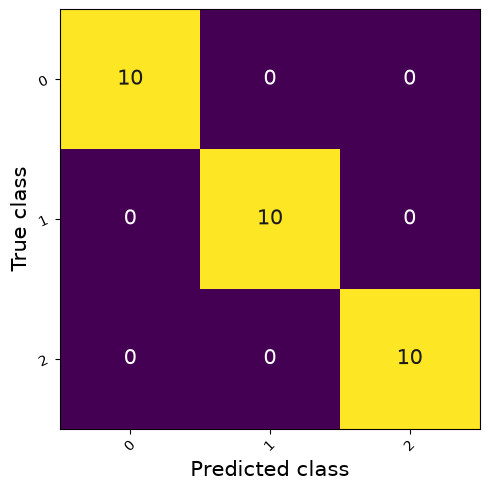

In [51]:
plot_confusion_matrix(matrix)

In [52]:
from pathlib import Path

In [53]:
MODEL_PATH=Path("models")
MODEL_PATH.mkdir(parents=True,exist_ok=True)

MODEL_NAME="iris_classification_model.pth"
MODEL_SAVE_PATH=MODEL_PATH/MODEL_NAME

torch.save(obj=model2.state_dict(),f=MODEL_SAVE_PATH)

In [54]:
model2.state_dict()

OrderedDict([('linear_layer_stack.0.weight',
              tensor([[ 0.0226, -0.1231, -0.4528, -0.4701],
                      [-0.2390, -0.2542,  0.1558, -0.1456],
                      [-0.0023,  0.4457,  0.4423,  0.7727],
                      [-0.2421, -0.2042,  0.1838, -0.3331],
                      [-0.3269, -0.0241, -0.1829, -0.3748],
                      [ 0.2419,  0.2943,  0.2267, -0.1764],
                      [-0.4631, -0.1821,  0.1273,  0.2358],
                      [-0.0632, -0.1977,  0.2786, -0.3982],
                      [ 0.3317, -0.4232,  0.3906,  0.4600],
                      [ 0.0424, -0.0942,  0.6855,  0.6865],
                      [ 0.6920,  0.6610, -0.4516, -0.9888],
                      [ 0.7397,  0.6749, -0.6044, -0.6993],
                      [-0.4931, -0.4093,  0.0966,  0.1330],
                      [ 0.1377, -0.1834,  0.8425,  0.6431],
                      [-0.2950, -0.0283,  0.1201,  0.1751],
                      [-0.3535,  0.1874, -0.2554, -0.41

In [55]:
loaded_model=IrısClassifier()

In [56]:
loaded_model.load_state_dict(torch.load(MODEL_SAVE_PATH))

<All keys matched successfully>

In [57]:
new_sample=np.array([[5.1,3.5,1.4,0.2]])
new_sample_tensor=torch.tensor(new_sample,dtype=torch.float32)
loaded_model.eval()
with torch.inference_mode():
    logits=loaded_model(new_sample_tensor)
    probs=torch.softmax(logits,dim=1)
    predicted_class=torch.argmax(probs,dim=1).item()
label_encoder.inverse_transform([predicted_class])[0]

'Iris-setosa'

In [58]:
df.tail()

,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
145,6.7,3.0,5.2,2.3,Iris-virginica
146,6.3,2.5,5.0,1.9,Iris-virginica
147,6.5,3.0,5.2,2.0,Iris-virginica
148,6.2,3.4,5.4,2.3,Iris-virginica
149,5.9,3.0,5.1,1.8,Iris-virginica
